In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.thickness import _walk_to_mask_edge, gaussian
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625






--- Processing beta = 0.25, t = 200 ---
Computing filtering (slow)...
IMF 1
IMF 2
IMF 3
IMF 4
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so


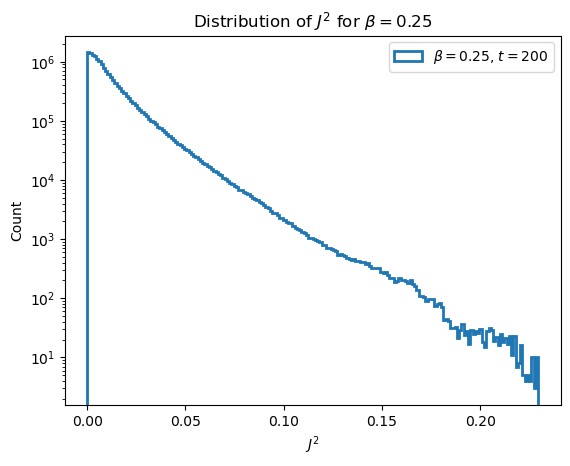

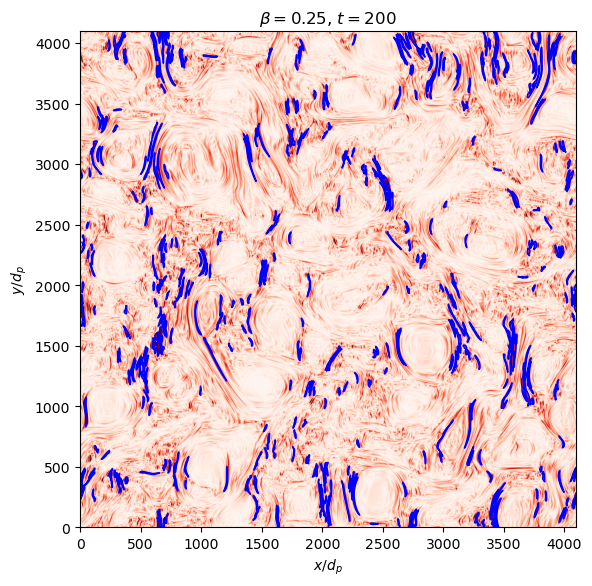

In [17]:
# -----------------------------
# USER SETTINGS
# -----------------------------
beta = 0.25                  # pick one: 0.0625, 1, or 16
times = [200]             # add more snapshots here, e.g. [100, 150, 200]
cache_dir = str(CACHE / "filtered_cache_Jz")
os.makedirs(cache_dir, exist_ok=True)

# storage (keyed by time)
J2_all = {}
mask_all = {}

# ----- FILTER PARAMETERS (depend on beta) -----
if beta == 0.0625:
    n_iter, Xi = 3, 2.0
elif beta == 0.25:
    n_iter, Xi = 3, 2.3
elif beta == 1:
    n_iter, Xi = 3, 2.5
elif beta == 4:
    n_iter, Xi = 3, 2.7
else:
    n_iter, Xi = 3, 3.0

base_path = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/'

# -----------------------------
# MAIN LOOP (over times only)
# -----------------------------
for time in times:
    print(f"\n--- Processing beta = {beta}, t = {time} ---")

    File_Bx = base_path + f'Bx_ApJ_t{time}.h5'
    File_By = base_path + f'By_ApJ_t{time}.h5'
    File_Bz = base_path + f'Bz_ApJ_t{time}.h5'

    with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:
        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"

    if os.path.exists(cache_file):
        print("Loading cached filtered fields...")
        data = np.load(cache_file)
        data_Bx_f = data['Bx']
        data_By_f = data['By']
        data_Bz_f = data['Bz']
    else:
        print("Computing filtering (slow)...")
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi
        )
        np.savez_compressed(
            cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f
        )

    # ----- CURRENT DENSITY -----
    Jx = partial_y_fft(data_Bz_f, dx)
    Jy = -partial_x_fft(data_Bz_f, dy)
    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    # J2 = Jx**2 + Jy**2 + Jz**2
    J2 = np.abs(Jz)

    plt.hist(J2.ravel(), bins=200, log=True,
             histtype='step', linewidth=2,
             label=fr'$\beta = {beta}$, $t = {time}$')

    # ----- CURRENT SHEET DETECTION -----
    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1

    # ----- MORPHOLOGICAL CLEANING -----
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(
        mask.astype(bool), min_size=500
    ).astype(int)

    J2_all[time] = J2
    mask_all[time] = mask

plt.legend()
plt.xlabel(r'$J^2$')
plt.ylabel('Count')
plt.title(fr'Distribution of $J^2$ for $\beta = {beta}$')
plt.show()

# -----------------------------
# COLOR SCALE
# -----------------------------
all_values = np.concatenate([v.ravel() for v in J2_all.values()])
vmax_global = np.percentile(all_values, 99)

# -----------------------------
# PLOT (one row of panels, one per time)
# -----------------------------
fig, axes = plt.subplots(
    1, len(times),
    figsize=(6 * len(times), 6),
    squeeze=False
)

for c, time in enumerate(times):
    ax = axes[0][c]
    im = ax.imshow(
        J2_all[time].T, cmap='Reds', origin='lower', vmax=vmax_global
    )
    ax.contour(
        mask_all[time].T, levels=[0.5], colors='blue', linewidths=1
    )
    ax.set_title(fr'$\beta = {beta}$, $t = {time}$')
    ax.set_xlabel(r'$x/d_p$')
    ax.set_ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig(RESULTS / f"J2_comparison_beta_{beta}.png", dpi=300)
plt.show()

In [18]:
cleaned_mask = mask_all[time]
J2 = J2_all[time]
labeled_mask, num_features = label(cleaned_mask)
print(f"[t={time}] Regions found:", num_features)

[t=200] Regions found: 394


[t=200] Regions found: 266
[t=200] (M1) regions: 264
[t=200] M1 mean=10.175, median=9.472, min=5.657, max=26.000
[t=200] M2 mean=11.113, median=7.000, min=4.000, max=81.000


/tmp/ipykernel_272449/1172737881.py:242: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])


[t=200] M3 mean=18.996, median=13.641, min=0.025, max=82.697


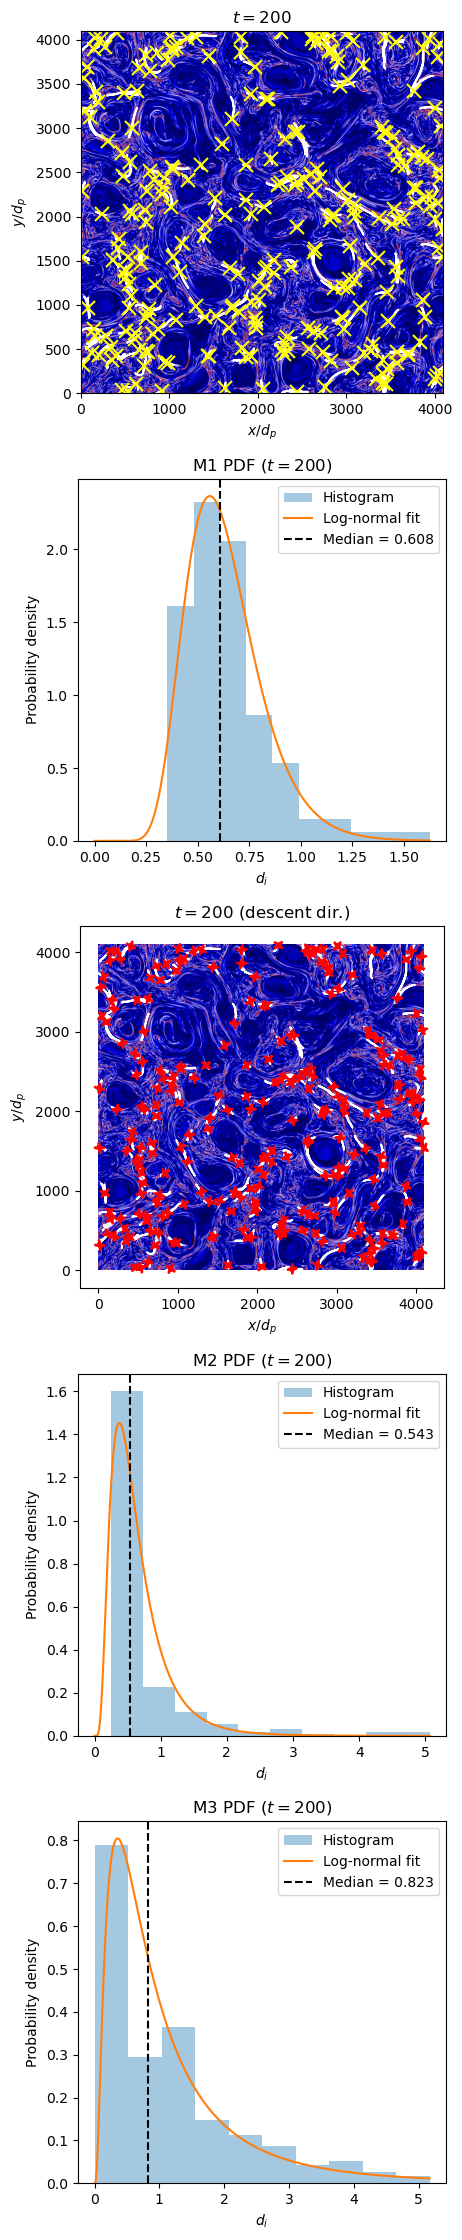

In [16]:
# # ---------- Gaussian model for M3 ----------
# def gaussian(t, A, mu, sigma, B):
#     return A * np.exp(-(t - mu)**2 / (2*sigma**2)) + B

# # ---------- M3 sampling parameters ----------
# max_len = 60
# step_px = 1

# # ---------- Pick which snapshot to analyse ----------
# time = 200   # must match a key you stored in J2_all / mask_all

# parent_save_folder = "gaussian_fits_J2_NR"
# os.makedirs(parent_save_folder, exist_ok=True)

# # ---------- Figure: 5 rows x 1 col ----------
# fig, axes = plt.subplots(5, 1, figsize=(4.5, 22.5))

# ax_img_m1  = axes[0]
# ax_hist_m1 = axes[1]
# ax_img_m2  = axes[2]
# ax_hist_m2 = axes[3]
# ax_hist_m3 = axes[4]

# cleaned_mask = mask_all[time]
# J2 = J2_all[time]

# # -----------------------------
# # CONNECTED REGIONS (for maxima)
# # -----------------------------
# labeled_mask, num_features = label(cleaned_mask)
# print(f"[t={time}] Regions found:", num_features)

# max_coords = []
# max_values = []

# for i in range(1, num_features + 1):
#     region_mask = (labeled_mask == i)
#     region_vals = J2[region_mask]
#     if region_vals.size == 0:
#         continue
#     max_pos = np.argmax(np.abs(region_vals))
#     max_values.append(region_vals[max_pos])
#     xs_r, ys_r = np.where(region_mask)
#     max_coords.append((xs_r[max_pos], ys_r[max_pos]))

# boundaries = find_boundaries(labeled_mask)

# # -----------------------------
# # ROW 0: FIELD + MAXIMA
# # -----------------------------
# ax_img_m1.imshow(J2.T, cmap='seismic', origin='lower', vmax=vmax_global)
# ax_img_m1.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)
# for x, y in max_coords:
#     ax_img_m1.plot(x, y, marker='x', markersize=10,
#                    markeredgewidth=1.5, color='yellow')
# ax_img_m1.set_title(rf'$t = {time}$')
# ax_img_m1.set_xlabel(r'$x/d_p$')
# ax_img_m1.set_ylabel(r'$y/d_p$')

# # -----------------------------
# # METHOD 1 THICKNESS (distance transform)
# # -----------------------------
# labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
# num_regions = labeled_mask_m1.max()
# print(f"[t={time}] (M1) regions:", num_regions)

# thicknesses_m1 = []
# for label_id in range(1, num_regions + 1):
#     region = (labeled_mask_m1 == label_id)
#     dist = ndi.distance_transform_edt(region)
#     thicknesses_m1.append(2 * dist.max())

# print(f"[t={time}] M1 mean={np.mean(thicknesses_m1):.3f}, "
#       f"median={np.median(thicknesses_m1):.3f}, "
#       f"min={np.min(thicknesses_m1):.3f}, max={np.max(thicknesses_m1):.3f}")

# # -----------------------------
# # ROW 1: M1 PDF + LOGNORMAL FIT
# # -----------------------------
# x_m1 = np.array(thicknesses_m1)
# x_m1 = x_m1[x_m1 > 0]
# x_m1_di = x_m1 / 16.0

# shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
# xs_fit_m1 = np.linspace(0, x_m1_di.max(), 300)

# ax_hist_m1.hist(x_m1_di, bins=10, density=True, alpha=0.4, label="Histogram")
# ax_hist_m1.plot(xs_fit_m1, lognorm.pdf(xs_fit_m1, shape_m1, loc_m1, scale_m1),
#                 label="Log-normal fit")
# ax_hist_m1.axvline(scale_m1, color='k', linestyle='--', linewidth=1.5,
#                    label=f"Median = {scale_m1:.3f}")
# ax_hist_m1.set_xlabel(r"$d_i$")
# ax_hist_m1.set_ylabel("Probability density")
# ax_hist_m1.set_title(rf'M1 PDF ($t = {time}$)')
# ax_hist_m1.legend()

# # -----------------------------
# # METHOD 2: STEEPEST-DESCENT DIRECTIONS
# # -----------------------------
# sigma = 3
# J2_smooth = gaussian_filter(J2, sigma=sigma)
# dJdx, dJdy = np.gradient(J2_smooth)

# descent_dirs = []
# for (x, y) in max_coords:
#     grad = np.array([dJdx[x, y], dJdy[x, y]])
#     if np.allclose(grad, 0):
#         descent_dirs.append(np.array([0.0, 0.0]))
#     else:
#         descent_dirs.append(-grad / np.linalg.norm(grad))

# # -----------------------------
# # ROW 2: FIELD + DESCENT ARROWS
# # -----------------------------
# ax_img_m2.imshow(J2.T, cmap='seismic', origin='lower',
#                  vmax=vmax_global, aspect='equal', zorder=0)
# ax_img_m2.contour(boundaries.T, levels=[0.5], colors='white',
#                   linewidths=1, zorder=2)

# factor = 200.0
# for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
#     start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
#     end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)
#     arrow = FancyArrowPatch(start, end, arrowstyle="<->",
#                             color="red", mutation_scale=10,
#                             linewidth=2, zorder=10)
#     ax_img_m2.add_patch(arrow)

# ax_img_m2.set_title(rf'$t = {time}$ (descent dir.)')
# ax_img_m2.set_xlabel(r'$x/d_p$')
# ax_img_m2.set_ylabel(r'$y/d_p$')

# # -----------------------------
# # METHOD 2 THICKNESS (walk along descent dir.)
# # -----------------------------
# distances = []
# step_size = 1
# max_steps = 1000

# for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
#     x0f, y0f = float(x0), float(y0)

#     xf, yf = x0f, y0f
#     steps = 0
#     while steps < max_steps:
#         xf_new = xf + dx * step_size
#         yf_new = yf + dy * step_size
#         xi, yi = int(round(xf_new)), int(round(yf_new))
#         if (xi < 0 or yi < 0 or
#             xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
#             break
#         if not cleaned_mask[xi, yi]:
#             break
#         xf, yf = xf_new, yf_new
#         steps += 1
#     dist_forward = np.hypot(xf - x0f, yf - y0f)

#     xb, yb = x0f, y0f
#     steps = 0
#     while steps < max_steps:
#         xb_new = xb - dx * step_size
#         yb_new = yb - dy * step_size
#         xi, yi = int(round(xb_new)), int(round(yb_new))
#         if (xi < 0 or yi < 0 or
#             xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
#             break
#         if not cleaned_mask[xi, yi]:
#             break
#         xb, yb = xb_new, yb_new
#         steps += 1
#     dist_backward = np.hypot(xb - x0f, yb - y0f)

#     distances.append((dist_backward, dist_forward))

# thicknesses_m2 = np.array([d[0] + d[1] for d in distances])
# thicknesses_m2 = thicknesses_m2[thicknesses_m2 > 0]

# print(f"[t={time}] M2 mean={np.mean(thicknesses_m2):.3f}, "
#       f"median={np.median(thicknesses_m2):.3f}, "
#       f"min={np.min(thicknesses_m2):.3f}, max={np.max(thicknesses_m2):.3f}")

# # -----------------------------
# # ROW 3: M2 PDF + LOGNORMAL FIT
# # -----------------------------
# x_m2_di = thicknesses_m2 / 16.0
# x_m2_di = x_m2_di[x_m2_di > 0]

# shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
# xs_fit_m2 = np.linspace(0, x_m2_di.max(), 300)

# ax_hist_m2.hist(x_m2_di, bins=10, density=True, alpha=0.4, label="Histogram")
# ax_hist_m2.plot(xs_fit_m2, lognorm.pdf(xs_fit_m2, shape_m2, loc_m2, scale_m2),
#                 label="Log-normal fit")
# ax_hist_m2.axvline(scale_m2, color='k', linestyle='--', linewidth=1.5,
#                    label=f"Median = {scale_m2:.3f}")
# ax_hist_m2.set_xlabel(r"$d_i$")
# ax_hist_m2.set_ylabel("Probability density")
# ax_hist_m2.set_title(rf'M2 PDF ($t = {time}$)')
# ax_hist_m2.legend()

# # -----------------------------
# # METHOD 3: FWHM via Gaussian fit along descent direction
# # -----------------------------
# fwhms = []
# xs_list = []
# vals_list = []
# popts_list = []

# for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
#     if dx == 0 and dy == 0:
#         fwhms.append(np.nan)
#         xs_list.append(np.array([]))
#         vals_list.append(np.array([]))
#         popts_list.append([np.nan]*4)
#         continue

#     xs, vals = [], []
#     for k in range(-max_len, max_len + 1):
#         xc = x + k * dx
#         yc = y + k * dy
#         xi, yi = int(round(xc)), int(round(yc))
#         if 0 <= xi < J2.shape[0] and 0 <= yi < J2.shape[1]:
#             xs.append(k)
#             vals.append(J2[xi, yi])

#     xs = np.array(xs)
#     vals = np.array(vals)
#     xs_list.append(xs)
#     vals_list.append(vals)

#     if len(vals) < 3:
#         fwhms.append(np.nan)
#         popts_list.append([np.nan]*4)
#         continue

#     A0 = vals.max() - vals.min()
#     mu0 = xs[np.argmax(vals)]
#     sigma0 = max_len / 4
#     B0 = vals.min()

#     try:
#         popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
#         A, mu, sigma_fit, B = popt
#         fwhm = 2 * np.sqrt(2 * np.log(2)) * sigma_fit
#         fwhms.append(fwhm)
#         popts_list.append(popt)
#     except RuntimeError:
#         fwhms.append(np.nan)
#         popts_list.append([np.nan]*4)

# # Save individual Gaussian fits
# beta_save_folder = os.path.join(parent_save_folder, f"t_{time}")
# os.makedirs(beta_save_folder, exist_ok=True)

# for i, (xs, vals, popt, fwhm) in enumerate(zip(xs_list, vals_list, popts_list, fwhms)):
#     if len(xs) == 0 or np.isnan(popt[0]):
#         continue
#     A, mu, sigma_fit, B = popt
#     x_dense = np.linspace(xs.min(), xs.max(), 500)
#     fit_curve = A * np.exp(-(x_dense - mu)**2 / (2*sigma_fit**2)) + B

#     fig_fit, ax_fit = plt.subplots()
#     ax_fit.plot(xs, vals, 'o', label="sampled profile")
#     ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
#     ax_fit.set_title(f"t={time}, sample {i} — FWHM = {fwhm:.2f} px")
#     ax_fit.set_xlabel("t (pixels)")
#     ax_fit.set_ylabel("Intensity")
#     ax_fit.legend()
#     fig_fit.savefig(os.path.join(beta_save_folder, f"fit_{i:03d}.png"))
#     plt.close(fig_fit)

# # Filter FWHMs
# fwhms_array = np.array(fwhms)
# thicknesses_m3 = fwhms_array[~np.isnan(fwhms_array)]
# thicknesses_m3 = thicknesses_m3[(thicknesses_m3 > 0) & (thicknesses_m3 <= 100)]

# print(f"[t={time}] M3 mean={np.mean(thicknesses_m3):.3f}, "
#       f"median={np.median(thicknesses_m3):.3f}, "
#       f"min={np.min(thicknesses_m3):.3f}, max={np.max(thicknesses_m3):.3f}")

# # -----------------------------
# # ROW 4: M3 PDF + LOGNORMAL FIT
# # -----------------------------
# x_m3_di = thicknesses_m3 / 16.0

# if x_m3_di.size > 0:
#     shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
#     xs_fit_m3 = np.linspace(0, x_m3_di.max(), 300)
#     ax_hist_m3.hist(x_m3_di, bins=10, density=True, alpha=0.4, label="Histogram")
#     ax_hist_m3.plot(xs_fit_m3, lognorm.pdf(xs_fit_m3, shape_m3, loc_m3, scale_m3),
#                     label="Log-normal fit")
#     ax_hist_m3.axvline(scale_m3, color='k', linestyle='--', linewidth=1.5,
#                        label=f"Median = {scale_m3:.3f}")
#     ax_hist_m3.legend()

# ax_hist_m3.set_xlabel(r"$d_i$")
# ax_hist_m3.set_ylabel("Probability density")
# ax_hist_m3.set_title(rf'M3 PDF ($t = {time}$)')

# plt.tight_layout()
# plt.savefig(f"J2_NR_M1_M2_M3_t{time}.png", dpi=300)
# plt.show()

In [19]:
import os
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import label
from skimage.segmentation import find_boundaries

# ---------- pick snapshot ----------
time = 200
J2 = J2_all[time]
cleaned_mask = mask_all[time]

# ---------- output folder ----------
save_folder = str(RESULTS / f"current_sheets_turbulence_Jz__t{time}")
os.makedirs(save_folder, exist_ok=True)

# ---------- label regions & find per-region maxima ----------
labeled_mask, num_features = label(cleaned_mask)
print(f"[t={time}] current sheets found:", num_features)

margin = 20  # pixels of padding around each sheet

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J2[region_mask]
    if region_vals.size == 0:
        continue

    max_pos = np.argmax(np.abs(region_vals))
    xs_r, ys_r = np.where(region_mask)
    mx, my = xs_r[max_pos], ys_r[max_pos]

    x0 = max(xs_r.min() - margin, 0)
    x1 = min(xs_r.max() + margin, J2.shape[0] - 1)
    y0 = max(ys_r.min() - margin, 0)
    y1 = min(ys_r.max() + margin, J2.shape[1] - 1)

    boundary_i = find_boundaries(region_mask)

    J2_crop = J2[x0:x1+1, y0:y1+1]
    bnd_crop = boundary_i[x0:x1+1, y0:y1+1]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(J2_crop.T, cmap='seismic', origin='lower',
              vmax=vmax_global, extent=[x0, x1, y0, y1])
    ax.contour(bnd_crop.T, levels=[0.5], colors='white', linewidths=1.2,
               extent=[x0, x1, y0, y1])
    ax.plot(mx, my, marker='x', markersize=12,
            markeredgewidth=2, color='yellow')

    ax.set_title(rf'CS #{i}  ($t = {time}$)')
    ax.set_xlabel(r'$x/d_p$')
    ax.set_ylabel(r'$y/d_p$')
    plt.tight_layout()
    plt.savefig(os.path.join(save_folder, f"CS_{i:03d}_t{time}.png"), dpi=200)
    plt.close(fig)

print(f"Saved {num_features} current-sheet images to '{save_folder}/'")

[t=200] current sheets found: 394
Saved 394 current-sheet images to 'current_sheets_turbulence_Jz__t200/'


[t=200] Regions found: 394
[t=200] (M1) regions: 392
[t=200] M1 mean=13.003, median=12.000, min=7.211, max=31.305
[t=200] M2 mean=14.218, median=10.000, min=5.000, max=166.000
[t=200] M3 mean=14.947, median=12.417, min=3.211, max=83.596


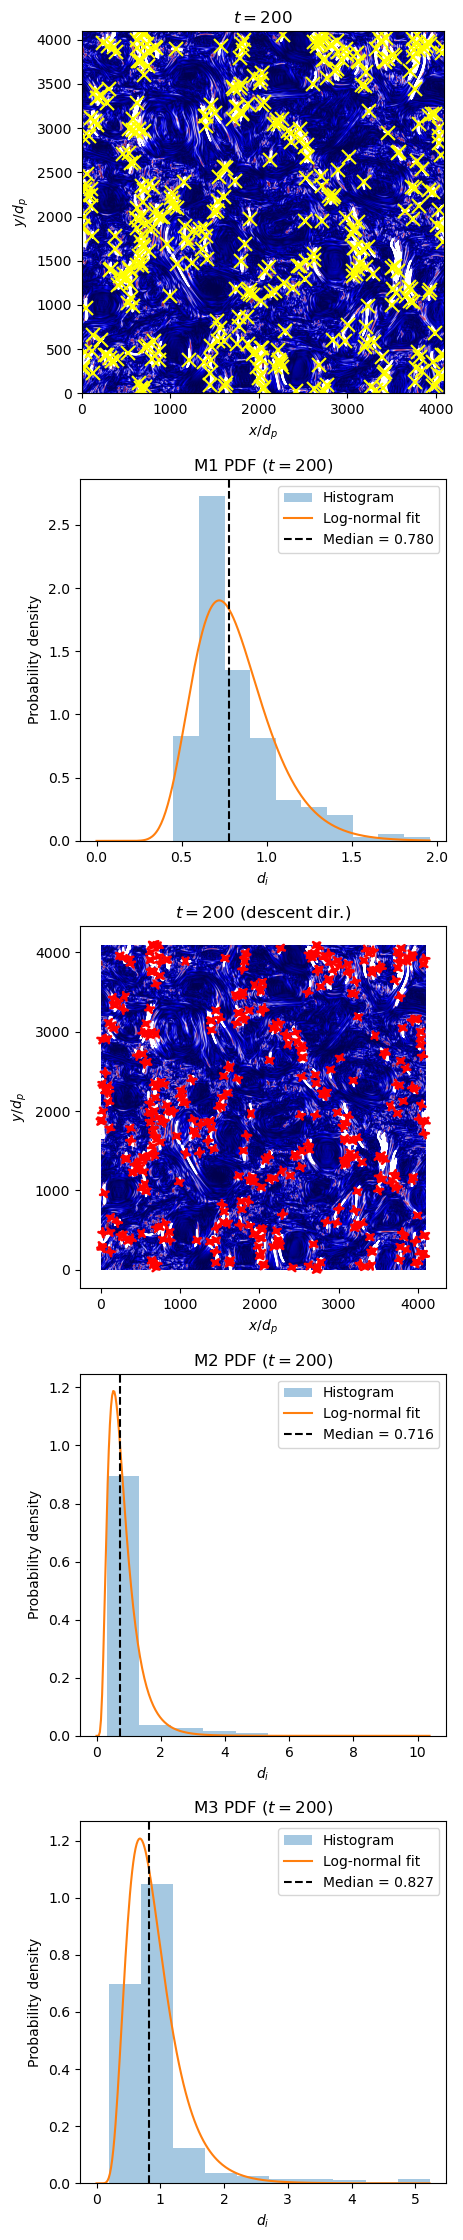

In [20]:
# ---------- Gaussian model for M3 ----------

# ---------- M3 sampling parameters ----------
max_len = 60
step_px = 1

# ---------- Pick which snapshot to analyse ----------
time = 200   # must match a key you stored in J2_all / mask_all

parent_save_folder = str(RESULTS / "gaussian_fits_J2_NR_one_beta")
os.makedirs(parent_save_folder, exist_ok=True)

# ---------- Figure: 5 rows x 1 col ----------
fig, axes = plt.subplots(5, 1, figsize=(4.5, 22.5))

ax_img_m1  = axes[0]
ax_hist_m1 = axes[1]
ax_img_m2  = axes[2]
ax_hist_m2 = axes[3]
ax_hist_m3 = axes[4]

cleaned_mask = mask_all[time]
J2 = J2_all[time]

# -----------------------------
# CONNECTED REGIONS (for maxima)
# -----------------------------
labeled_mask, num_features = label(cleaned_mask)
print(f"[t={time}] Regions found:", num_features)

max_coords = []
max_values = []

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J2[region_mask]
    if region_vals.size == 0:
        continue
    max_pos = np.argmax(np.abs(region_vals))
    max_values.append(region_vals[max_pos])
    xs_r, ys_r = np.where(region_mask)
    max_coords.append((xs_r[max_pos], ys_r[max_pos]))

boundaries = find_boundaries(labeled_mask)

# -----------------------------
# ROW 0: FIELD + MAXIMA
# -----------------------------
ax_img_m1.imshow(J2.T, cmap='seismic', origin='lower', vmax=vmax_global)
ax_img_m1.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)
for x, y in max_coords:
    ax_img_m1.plot(x, y, marker='x', markersize=10,
                   markeredgewidth=1.5, color='yellow')
ax_img_m1.set_title(rf'$t = {time}$')
ax_img_m1.set_xlabel(r'$x/d_p$')
ax_img_m1.set_ylabel(r'$y/d_p$')

# -----------------------------
# METHOD 1 THICKNESS (distance transform)
# -----------------------------
labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask_m1.max()
print(f"[t={time}] (M1) regions:", num_regions)

thicknesses_m1 = []
for label_id in range(1, num_regions + 1):
    region = (labeled_mask_m1 == label_id)
    dist = ndi.distance_transform_edt(region)
    thicknesses_m1.append(2 * dist.max())

print(f"[t={time}] M1 mean={np.mean(thicknesses_m1):.3f}, "
      f"median={np.median(thicknesses_m1):.3f}, "
      f"min={np.min(thicknesses_m1):.3f}, max={np.max(thicknesses_m1):.3f}")

# -----------------------------
# ROW 1: M1 PDF + LOGNORMAL FIT
# -----------------------------
x_m1 = np.array(thicknesses_m1)
x_m1 = x_m1[x_m1 > 0]
x_m1_di = x_m1 / 16.0

shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
xs_fit_m1 = np.linspace(0, x_m1_di.max(), 300)

ax_hist_m1.hist(x_m1_di, bins=10, density=True, alpha=0.4, label="Histogram")
ax_hist_m1.plot(xs_fit_m1, lognorm.pdf(xs_fit_m1, shape_m1, loc_m1, scale_m1),
                label="Log-normal fit")
ax_hist_m1.axvline(scale_m1, color='k', linestyle='--', linewidth=1.5,
                   label=f"Median = {scale_m1:.3f}")
ax_hist_m1.set_xlabel(r"$d_i$")
ax_hist_m1.set_ylabel("Probability density")
ax_hist_m1.set_title(rf'M1 PDF ($t = {time}$)')
ax_hist_m1.legend()

# -----------------------------
# METHOD 2: STEEPEST-DESCENT DIRECTIONS
# -----------------------------
sigma = 3
J2_smooth = gaussian_filter(J2, sigma=sigma)
dJdx, dJdy = np.gradient(J2_smooth)

descent_dirs = []
for (x, y) in max_coords:
    grad = np.array([dJdx[x, y], dJdy[x, y]])
    if np.allclose(grad, 0):
        descent_dirs.append(np.array([0.0, 0.0]))
    else:
        descent_dirs.append(-grad / np.linalg.norm(grad))

# -----------------------------
# ROW 2: FIELD + DESCENT ARROWS
# -----------------------------
ax_img_m2.imshow(J2.T, cmap='seismic', origin='lower',
                 vmax=vmax_global, aspect='equal', zorder=0)
ax_img_m2.contour(boundaries.T, levels=[0.5], colors='white',
                  linewidths=1, zorder=2)

factor = 200.0
for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
    end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)
    arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                            color="red", mutation_scale=10,
                            linewidth=2, zorder=10)
    ax_img_m2.add_patch(arrow)

ax_img_m2.set_title(rf'$t = {time}$ (descent dir.)')
ax_img_m2.set_xlabel(r'$x/d_p$')
ax_img_m2.set_ylabel(r'$y/d_p$')

# -----------------------------
# METHOD 2 THICKNESS (walk along descent dir.)
# -----------------------------
distances = []
step_size = 1
max_steps = 1000

for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
    x0f, y0f = float(x0), float(y0)

    xf, yf = x0f, y0f
    steps = 0
    while steps < max_steps:
        xf_new = xf + dx * step_size
        yf_new = yf + dy * step_size
        xi, yi = int(round(xf_new)), int(round(yf_new))
        if (xi < 0 or yi < 0 or
            xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xf, yf = xf_new, yf_new
        steps += 1
    dist_forward = np.hypot(xf - x0f, yf - y0f)

    xb, yb = x0f, y0f
    steps = 0
    while steps < max_steps:
        xb_new = xb - dx * step_size
        yb_new = yb - dy * step_size
        xi, yi = int(round(xb_new)), int(round(yb_new))
        if (xi < 0 or yi < 0 or
            xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xb, yb = xb_new, yb_new
        steps += 1
    dist_backward = np.hypot(xb - x0f, yb - y0f)

    distances.append((dist_backward, dist_forward))

thicknesses_m2 = np.array([d[0] + d[1] for d in distances])
thicknesses_m2 = thicknesses_m2[thicknesses_m2 > 0]

print(f"[t={time}] M2 mean={np.mean(thicknesses_m2):.3f}, "
      f"median={np.median(thicknesses_m2):.3f}, "
      f"min={np.min(thicknesses_m2):.3f}, max={np.max(thicknesses_m2):.3f}")

# -----------------------------
# ROW 3: M2 PDF + LOGNORMAL FIT
# -----------------------------
x_m2_di = thicknesses_m2 / 16.0
x_m2_di = x_m2_di[x_m2_di > 0]

shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
xs_fit_m2 = np.linspace(0, x_m2_di.max(), 300)

ax_hist_m2.hist(x_m2_di, bins=10, density=True, alpha=0.4, label="Histogram")
ax_hist_m2.plot(xs_fit_m2, lognorm.pdf(xs_fit_m2, shape_m2, loc_m2, scale_m2),
                label="Log-normal fit")
ax_hist_m2.axvline(scale_m2, color='k', linestyle='--', linewidth=1.5,
                   label=f"Median = {scale_m2:.3f}")
ax_hist_m2.set_xlabel(r"$d_i$")
ax_hist_m2.set_ylabel("Probability density")
ax_hist_m2.set_title(rf'M2 PDF ($t = {time}$)')
ax_hist_m2.legend()

# =====================================================================
# METHOD 3: FWHM via Gaussian fit along the steepest-descent direction
#   FIXES vs the original:
#   - sub-pixel line sampling (no int(round()) -> orientation-independent)
#   - window adaptively bounded to the mask edge (+margin), not a blind +/-60 px
#   - bounded Gaussian fit + data-driven sigma0 so sigma can't run into the background
#
# Drop-in replacement for everything from the old "METHOD 3" comment down to
# (and including) the M3 print. ROW 4 plotting below it is UNCHANGED.
# Assumes max_coords, descent_dirs (unit vectors), J2, cleaned_mask,
# parent_save_folder, time, gaussian(), curve_fit, ndi, np, plt, os already exist.
# =====================================================================

# ---------- M3 sampling parameters (all tunable) ----------
max_len      = 60      # hard cap on the half-window (px)
subpix_step  = 0.5     # sampling step along the profile (px, sub-pixel)
margin_frac  = 0.5     # extend the window this fraction past the mask edge
min_half     = 6.0     # floor on the half-window (px) so thin sheets get baseline


fwhms      = []
xs_list    = []
vals_list  = []
popts_list = []

for (x, y), (dx, dy) in zip(max_coords, descent_dirs):

    # skip undefined descent direction
    if dx == 0 and dy == 0:
        fwhms.append(np.nan)
        xs_list.append(np.array([]))
        vals_list.append(np.array([]))
        popts_list.append([np.nan] * 4)
        continue

    # ----- adaptive half-windows: walk to the mask edge each way, then +margin -----
    len_f = _walk_to_mask_edge(cleaned_mask, x, y,  dx,  dy)
    len_b = _walk_to_mask_edge(cleaned_mask, x, y, -dx, -dy)
    half_f = min(max_len, max(min_half, len_f * (1.0 + margin_frac)))
    half_b = min(max_len, max(min_half, len_b * (1.0 + margin_frac)))

    # ----- sub-pixel profile of the RAW J2 along the descent line (periodic) -----
    xs = np.arange(-half_b, half_f + subpix_step, subpix_step)
    x_coord = x + xs * dx
    y_coord = y + xs * dy
    vals = ndi.map_coordinates(
        J2, np.vstack([x_coord, y_coord]),
        order=1, mode='grid-wrap'        # order=1 avoids overshoot at steep edges
    )

    xs_list.append(xs)
    vals_list.append(vals)

    if len(vals) < 4:
        fwhms.append(np.nan)
        popts_list.append([np.nan] * 4)
        continue

    # ----- initial guesses -----
    B0 = float(vals.min())
    A0 = float(vals.max() - vals.min())
    if A0 <= 0:
        fwhms.append(np.nan)
        popts_list.append([np.nan] * 4)
        continue
    mu0 = float(xs[np.argmax(vals)])

    # data-driven sigma0 from the half-maximum width (replaces the wide max_len/4 guess)
    above = np.where(vals >= B0 + 0.5 * A0)[0]
    if above.size >= 2:
        sigma0 = max(1.0, (xs[above[-1]] - xs[above[0]]) / 2.3548)
    else:
        sigma0 = max(2.0, (half_f + half_b) / 6.0)

    span = float(xs.max() - xs.min())
    sigma0 = min(sigma0, 0.99 * span)

    # ----- bounded fit: A>=0, mu inside window, 0<sigma<=span, B free -----
    bounds = ([0.0,    xs.min() - 1.0, 1e-3, -np.inf],
              [np.inf, xs.max() + 1.0, span,  np.inf])
    try:
        popt, _ = curve_fit(
            gaussian, xs, vals,
            p0=[A0, mu0, sigma0, B0],
            bounds=bounds, maxfev=10000
        )
        sigma_fit = popt[2]
        fwhms.append(2.0 * np.sqrt(2.0 * np.log(2.0)) * abs(sigma_fit))
        popts_list.append(popt)
    except (RuntimeError, ValueError):
        fwhms.append(np.nan)
        popts_list.append([np.nan] * 4)

# ----------------------------------------------------------------------
# Save individual Gaussian fits (same behaviour as before)
# ----------------------------------------------------------------------
beta_save_folder = os.path.join(parent_save_folder, f"t_{time}")
os.makedirs(beta_save_folder, exist_ok=True)

for i, (xs, vals, popt, fwhm) in enumerate(zip(xs_list, vals_list, popts_list, fwhms)):
    if len(xs) == 0 or np.isnan(popt[0]):
        continue
    A, mu, sigma_fit, B = popt
    x_dense = np.linspace(xs.min(), xs.max(), 500)
    fit_curve = A * np.exp(-(x_dense - mu)**2 / (2 * sigma_fit**2)) + B

    fig_fit, ax_fit = plt.subplots()
    ax_fit.plot(xs, vals, 'o', ms=3, label="sampled profile")
    ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
    ax_fit.set_title(f"t={time}, sample {i} — FWHM = {fwhm:.2f} px")
    ax_fit.set_xlabel("distance along descent (px)")
    ax_fit.set_ylabel(r"$J^2$")
    ax_fit.legend()
    fig_fit.savefig(os.path.join(beta_save_folder, f"fit_{i:03d}.png"))
    plt.close(fig_fit)

# ----------------------------------------------------------------------
# Filter FWHMs
# ----------------------------------------------------------------------
fwhms_array = np.array(fwhms)
thicknesses_m3 = fwhms_array[~np.isnan(fwhms_array)]
thicknesses_m3 = thicknesses_m3[(thicknesses_m3 > 0) & (thicknesses_m3 <= 100)]

print(f"[t={time}] M3 mean={np.mean(thicknesses_m3):.3f}, "
      f"median={np.median(thicknesses_m3):.3f}, "
      f"min={np.min(thicknesses_m3):.3f}, max={np.max(thicknesses_m3):.3f}")

# -----------------------------
# ROW 4: M3 PDF + LOGNORMAL FIT
# -----------------------------
x_m3_di = thicknesses_m3 / 16.0

if x_m3_di.size > 0:
    shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
    xs_fit_m3 = np.linspace(0, x_m3_di.max(), 300)
    ax_hist_m3.hist(x_m3_di, bins=10, density=True, alpha=0.4, label="Histogram")
    ax_hist_m3.plot(xs_fit_m3, lognorm.pdf(xs_fit_m3, shape_m3, loc_m3, scale_m3),
                    label="Log-normal fit")
    ax_hist_m3.axvline(scale_m3, color='k', linestyle='--', linewidth=1.5,
                       label=f"Median = {scale_m3:.3f}")
    ax_hist_m3.legend()

ax_hist_m3.set_xlabel(r"$d_i$")
ax_hist_m3.set_ylabel("Probability density")
ax_hist_m3.set_title(rf'M3 PDF ($t = {time}$)')

plt.tight_layout()
plt.savefig(RESULTS / f"J2_NR_M1_M2_M3_t{time}.png", dpi=300)
plt.show()

unweighted fit (n=5, dof=3):  b = 0.197 +/- 0.006   a = 5.320
log-space residuals = [-0.026  0.013  0.033  0.001 -0.021]
check the residuals for SYSTEMATIC curvature (sign pattern) -> would mean a power law misfits
MC: b = 0.197  [0.191, 0.203]  (68%)


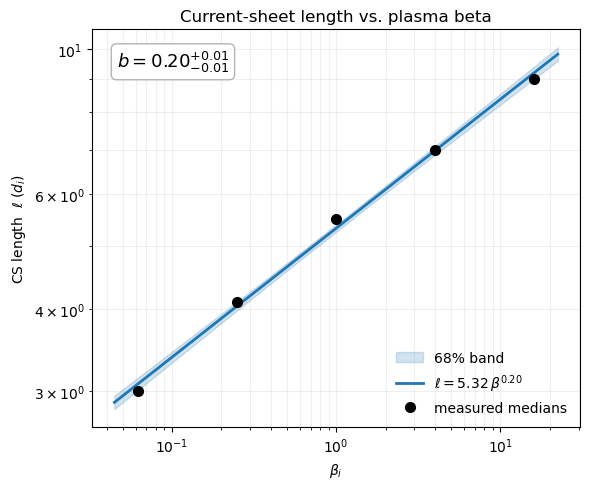

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================================
# INPUT  (now 5 points)
# ======================================================================
beta = np.array([0.0625, 0.25, 1.0, 4.0, 16.0])   # PLACEHOLDER betas - use yours
y    = np.array([3.0, 4.1, 5.5, 7.0, 9.0])         # CS length medians (PLACEHOLDER)

# Leave None until you have bootstrap sigmas. Set to a 5-element array of
# 1-sigma values (same units as y) to use measurement weighting instead.
sigma = None

assert np.all(y > 0), "log-log power-law fit needs all lengths > 0"
logx, logy = np.log(beta), np.log(y)
n = len(beta)
dof = n - 2

# ======================================================================
# Fit  y = a * beta**b   (c = 0  ->  log y = log a + b log beta)
# ======================================================================
if sigma is None:
    coeffs, cov = np.polyfit(logx, logy, 1, cov=True)          # cov scaled by residual (dof=3)
    b, log_a = coeffs
    resid = logy - (log_a + b * logx)
    sig_ly = np.full(n, np.sqrt(np.sum(resid**2) / dof))       # homoscedastic scatter estimate
    w = None
    weighted = False
else:
    sig_ly = sigma / y
    w = 1.0 / sig_ly
    coeffs, cov = np.polyfit(logx, logy, 1, w=w, cov='unscaled')
    b, log_a = coeffs
    resid = logy - (log_a + b * logx)
    weighted = True

a = np.exp(log_a)
b_se = np.sqrt(cov[0, 0])

print(f"{'weighted' if weighted else 'unweighted'} fit (n={n}, dof={dof}):  b = {b:.3f} +/- {b_se:.3f}   a = {a:.3f}")
print(f"log-space residuals = {np.round(resid, 3)}")
if weighted:
    chi2 = np.sum((resid / sig_ly) ** 2)
    print(f"reduced chi2 = {chi2/dof:.2f}  (>>1 => power law is the wrong shape)")
else:
    print("check the residuals for SYSTEMATIC curvature (sign pattern) -> would mean a power law misfits")

# ======================================================================
# Monte-Carlo error + confidence band (unified for both modes)
#   sigma given  -> resample each point by its measurement sigma
#   sigma None   -> resample by the fitted homoscedastic scatter
# ======================================================================
rng = np.random.default_rng(0)
N_mc = 10000
xgrid = np.logspace(np.log10(beta.min() / 1.4), np.log10(beta.max() * 1.4), 200)
curves = np.empty((N_mc, xgrid.size)); b_samp = np.empty(N_mc)
for i in range(N_mc):
    logy_i = logy + rng.normal(0.0, sig_ly)
    if weighted:
        bi, log_ai = np.polyfit(logx, logy_i, 1, w=w)
    else:
        bi, log_ai = np.polyfit(logx, logy_i, 1)
    b_samp[i] = bi; curves[i] = np.exp(log_ai) * xgrid ** bi
b_med = np.median(b_samp); b_lo, b_hi = np.percentile(b_samp, [16, 84])
band_lo, band_hi = np.percentile(curves, [16, 84], axis=0)
print(f"MC: b = {b_med:.3f}  [{b_lo:.3f}, {b_hi:.3f}]  (68%)")

# ======================================================================
# Plot
# ======================================================================
fig, ax = plt.subplots(figsize=(6, 5))
ax.fill_between(xgrid, band_lo, band_hi, color='C0', alpha=0.20, label='68% band')
ax.plot(xgrid, a * xgrid ** b, color='C0', lw=2, label=fr'$\ell = {a:.2f}\,\beta^{{{b:.2f}}}$')
if sigma is None:
    ax.plot(beta, y, 'o', color='k', ms=7, zorder=5, label='measured medians')
else:
    ax.errorbar(beta, y, yerr=sigma, fmt='o', color='k', ms=7, capsize=4, lw=1.5,
                zorder=5, label='measured medians')
ax.text(0.05, 0.95, fr'$b = {b_med:.2f}^{{+{b_hi - b_med:.2f}}}_{{-{b_med - b_lo:.2f}}}$',
        transform=ax.transAxes, va='top', fontsize=13,
        bbox=dict(boxstyle='round', fc='white', ec='0.7'))
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$\beta_i$')
ax.set_ylabel(r'CS length  $\ell\ (d_i)$')
ax.set_title('Current-sheet length vs. plasma beta')
ax.legend(frameon=False, loc='lower right')
ax.grid(True, which='both', alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS / 'cs_length_vs_beta_powerlaw.png', dpi=300)
plt.show()